# Transformer: phân loại cảm xúc IMDB bằng DistilBERT (fine-tune)

**Thế mạnh của Transformer:**
1. **Self-attention**: mỗi từ nhìn trực tiếp **mọi từ khác** trong câu cùng lúc, nên quan hệ xa (đầu câu với cuối câu) chỉ cách nhau một bước, không phải đi qua hàng trăm bước như RNN/LSTM.
2. **Tính toán song song**: không phải đợi từng bước tuần tự nên tận dụng GPU rất tốt và huấn luyện được trên dữ liệu khổng lồ.
3. **Pretrained**: mô hình được huấn luyện trước trên lượng văn bản rất lớn, đã "biết tiếng Anh". Ta chỉ cần fine-tune cho bài toán cụ thể (transfer learning). Đây là lợi thế mà RNN/LSTM tự train từ đầu không có.

**Self-attention:** mỗi từ tạo 3 vector: Query (Q, "tôi đang tìm gì"), Key (K, "tôi có gì") và Value (V, "nội dung của tôi"). Độ liên quan giữa hai từ là tích vô hướng Q·K; điểm này qua softmax để thành trọng số, rồi lấy trung bình có trọng số của các V:

`Attention(Q, K, V) = softmax(Q·Kᵀ / √d) · V`

**Điểm yếu:** chi phí attention tăng theo **bình phương** độ dài chuỗi, nên thường phải cắt review ở 256 token (khoảng 190 từ).

**Mô hình:** DistilBERT (6 lớp Transformer, 66 triệu tham số), bản rút gọn của BERT, đủ nhẹ để fine-tune trên GPU 4 GB.

In [1]:
import common as C
C.set_seed(0)
print(C.DEVICE)

cuda


## 1. Dữ liệu
Dùng cùng chia train/val/test với notebook LSTM. Token hóa bằng WordPiece của DistilBERT (tách từ hiếm thành mảnh nhỏ), cắt tối đa 256 token. Lần đầu mất khoảng 30 giây để token hóa và tải mô hình.

In [2]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('distilbert/distilbert-base-uncased')
print(tok.tokenize('This movie was unbelievably entertaining!'))
loaders = C.bert_loaders(max_len=256, batch_size=16)
print({k: len(v.dataset) for k, v in loaders.items()})

['this', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'entertaining', '!']
{'train': 22500, 'val': 2500, 'test': 25000}


## 2. Mô hình
DistilBERT pretrained + đầu phân loại 2 lớp (khởi tạo mới). Cảnh báo `MISSING` về `classifier.weight` khi tải mô hình là bình thường: đó chính là đầu phân loại mới sẽ được học.

In [3]:
model = C.DistilBertClassifier()
print(f'{C.n_params(model):.1f}M tham số')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


67.0M tham số


## 3. Huấn luyện (fine-tune)
Learning rate nhỏ (3e-5) vì mô hình đã biết sẵn ngôn ngữ, chỉ cần chỉnh nhẹ. 2 epoch, mixed precision.

ep 01/2 | train loss 0.313 acc 0.871 | val loss 0.233 acc 0.900


ep 02/2 | train loss 0.161 acc 0.947 | val loss 0.294 acc 0.914
Thời gian train: 9.5 phút


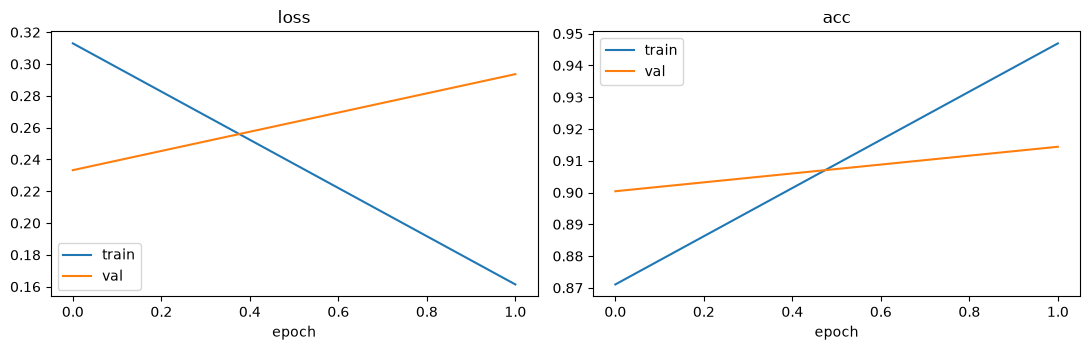

In [4]:
model, hist, t = C.train_classifier('distilbert_imdb', model, loaders, epochs=2, lr=3e-5)
print(f'Thời gian train: {t/60:.1f} phút')
C.plot_history(hist)

## 4. Đánh giá trên tập test (25.000 review)

              precision    recall  f1-score   support

    negative     0.9143    0.9179    0.9161     12500
    positive     0.9176    0.9139    0.9158     12500

    accuracy                         0.9159     25000
   macro avg     0.9159    0.9159    0.9159     25000
weighted avg     0.9159    0.9159    0.9159     25000



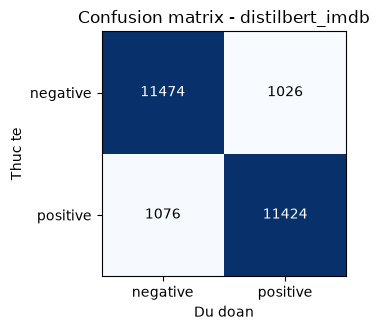

[distilbert_imdb] test accuracy 0.9159 | macro F1 0.9159


In [5]:
res = C.evaluate_classifier('distilbert_imdb', model, loaders['test'], hist, t)

In [6]:
C.predict_texts_bert(model, [
    'A wonderful, moving film with brilliant acting.',
    'Total waste of time, awful acting and a boring plot.',
    'I expected to hate it, but it turned out to be surprisingly good.',
    'The first hour was slow and dull, however the ending completely won me over.',
])

positive (1.00) | A wonderful, moving film with brilliant acting.
negative (1.00) | Total waste of time, awful acting and a boring plot.
positive (0.99) | I expected to hate it, but it turned out to be surprisingly good.
positive (0.95) | The first hour was slow and dull, however the ending completely won me over.


## 5. Nhận xét

**Kết quả trên tập test (25.000 review):** DistilBERT fine-tune đạt **accuracy 91,59%** và macro F1 0,916. Mô hình có 66,96 triệu tham số, train 2 epoch trong khoảng 9,5 phút.

**Quá trình huấn luyện:** chỉ sau 1 epoch val accuracy đã đạt 90,0%, epoch 2 đạt 91,4%. Đây là tác dụng của pretrained: mô hình đã hiểu ngôn ngữ nên chỉ cần chỉnh nhẹ. Train accuracy lên 94,7% trong khi val loss tăng từ 0,233 lên 0,294 dù accuracy vẫn tăng, dấu hiệu mô hình bắt đầu quá tự tin, nên 2 epoch là hợp lý và train thêm có thể không có lợi.

**Các câu thử:** DistilBERT đoán **đúng cả 4 câu**, kể cả hai câu có chuyển ý ("tưởng sẽ ghét nhưng hóa ra hay" với độ tin cậy 0,99, và "đầu chán nhưng đoạn kết thắng tôi" với 0,95), hai câu mà BiLSTM ở notebook 02 đoán sai. Chỉ có 4 câu nên đây là minh họa, không phải bằng chứng thống kê.

**So với BiLSTM (87,66%):** cao hơn khoảng 3,9 điểm accuracy. Đổi lại, DistilBERT có số tham số gấp khoảng 24 lần (66,96M so với 2,82M) và thời gian train gấp khoảng 6,6 lần (khoảng 9,5 phút so với 1,4 phút).

**Lưu ý khi diễn giải:** mức cải thiện đến từ **cả hai** yếu tố: kiến trúc Transformer (attention) và việc được pretrained trên lượng văn bản lớn. Thí nghiệm này không tách riêng được hai yếu tố. Một Transformer train từ đầu trên 22.500 review có thể không vượt được LSTM. Kết quả là một lần chạy với một seed.

**Điểm yếu cần nhớ:** review bị cắt ở 256 token (khoảng 190 từ) vì chi phí attention tăng theo bình phương độ dài, và mô hình nặng hơn nhiều so với LSTM.

**Kết luận:** Transformer pretrained cho độ chính xác cao nhất (91,6%) và hiểu ngữ cảnh tốt hơn trên các câu thử, với giá là kích thước và chi phí tính toán lớn hơn.